# 03. Mô hình scikit-learn và đối chuẩn với bản tự cài đặt

Nội dung: chọn siêu tham số `C` bằng GridSearchCV, so sánh hệ số, số vòng lặp, thời gian chạy và chỉ số đánh giá giữa hai bản cài đặt.

Tương ứng mục 4.5 của báo cáo.

In [1]:
import os, sys
# Chạy từ thư mục notebooks/: chuyển về thư mục gốc dự án để đường dẫn tương đối hoạt động
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.insert(0, os.getcwd())

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from src.data import preprocess as pp
from src.models.logistic_regression_scratch import LogisticRegressionScratch
from src.models import logistic_regression_sklearn as skm
from src.models import evaluate as ev
from src.utils import visualization as viz

data = pp.run()

Số mẫu gốc: 1599 | giá trị thiếu: 0 | bản ghi trùng: 240
Sau làm sạch: 1359 mẫu | train: 1087 (575 nhãn 1) | test: 272 (144 nhãn 1)


## 1. Chọn C bằng GridSearchCV

Kiểm định chéo 5 phần phân tầng trên tập huấn luyện; chuẩn hóa nằm trong pipeline nên mỗi fold tự học tham số chuẩn hóa.

In [2]:
search = skm.grid_search(data.X_train_raw, data.y_train)
print("C tốt nhất:", search.best_params_["logisticregression__C"],
      "| accuracy CV:", round(search.best_score_, 4))
skm.grid_results(search).round(4)

C tốt nhất: 1 | accuracy CV: 0.7452


,C,mean_score,std_score
0,0.001,0.7268,0.0334
1,0.010,0.7323,0.0342
2,0.100,0.7433,0.0377
3,1.000,0.7452,0.0392
4,10.000,0.7443,0.0400
5,100.000,0.7443,0.0400
6,1000.000,0.7433,0.0390


Chênh lệch giữa các giá trị C nhỏ hơn độ lệch chuẩn giữa các fold, nên điều chuẩn L2 ảnh hưởng rất ít đến mô hình này.

## 2. Huấn luyện scikit-learn (C = 1) và bản tự cài đặt trên cùng dữ liệu

In [3]:
sk_model = skm.build_model(C=1.0, tol=1e-12).fit(data.X_train, data.y_train)
scratch = LogisticRegressionScratch(lr=0.5, n_iter=50000, lam=1.0, tol=1e-12).fit(data.X_train, data.y_train)

coef = ev.compare_coefficients(data.feature_names, scratch.w, scratch.b,
                               sk_model.coef_[0], sk_model.intercept_[0])
display(coef.round(6))
print("Chênh lệch hệ số lớn nhất:", f"{coef.abs_diff.max():.2e}")

,scratch,sklearn,abs_diff
fixed acidity,0.195574,0.195512,0.000062
volatile acidity,-0.476830,-0.476830,0.000000
citric acid,-0.139539,-0.139529,0.000010
residual sugar,0.057124,0.057108,0.000016
chlorides,-0.216754,-0.216760,0.000006
free sulfur dioxide,0.183119,0.183124,0.000006
total sulfur dioxide,-0.517388,-0.517396,0.000008
density,-0.076441,-0.076389,0.000052
pH,-0.073976,-0.074009,0.000033
sulphates,0.476929,0.476921,0.000008


Chênh lệch hệ số lớn nhất: 6.24e-05


## 3. So sánh số vòng lặp, thời gian chạy, hàm mất mát

In [4]:
t_scratch = ev.time_fit(lambda: LogisticRegressionScratch(lr=0.5, n_iter=50000, lam=1.0, tol=1e-12).fit(data.X_train, data.y_train))
t_sk = ev.time_fit(lambda: skm.build_model(C=1.0, tol=1e-12).fit(data.X_train, data.y_train))
pd.DataFrame({
    "tu_cai_dat (GD)": [len(scratch.history), round(t_scratch, 4), round(scratch.history[-1], 6)],
    "scikit-learn (L-BFGS)": [int(sk_model.n_iter_[0]), round(t_sk, 4), None],
}, index=["so_vong_lap", "thoi_gian_giay", "loss_cuoi"])

,tu_cai_dat (GD),scikit-learn (L-BFGS)
so_vong_lap,1354.000000,25.0000
thoi_gian_giay,0.076200,0.0027
loss_cuoi,0.514111,NaN


Thời gian phụ thuộc máy tính nên chỉ có giá trị tương đối. L-BFGS cần ít vòng lặp hơn nhiều so với Gradient Descent thuần túy.

## 4. Đánh giá trên tập kiểm tra

In [5]:
p_sk = sk_model.predict_proba(data.X_test)[:, 1]
p_sc = scratch.predict_proba(data.X_test)
print("Nhãn dự đoán trùng nhau:", int((sk_model.predict(data.X_test) == scratch.predict(data.X_test)).sum()), "/", len(data.y_test))
print("Chênh xác suất lớn nhất:", f"{np.abs(p_sk - p_sc).max():.2e}")
print(f"Mốc accuracy: {ev.majority_baseline(data.y_test):.4f}")
pd.DataFrame({"tu_cai_dat": ev.compute_metrics(data.y_test, p_sc),
              "scikit-learn": ev.compute_metrics(data.y_test, p_sk)}).round(4)

Nhãn dự đoán trùng nhau: 272 / 272
Chênh xác suất lớn nhất: 1.49e-05
Mốc accuracy: 0.5294


,tu_cai_dat,scikit-learn
accuracy,0.7353,0.7353
precision,0.7609,0.7609
recall,0.7292,0.7292
f1,0.7447,0.7447
roc_auc,0.8116,0.8117
log_loss,0.5241,0.5241
TN,95.0000,95.0000
FP,33.0000,33.0000
FN,39.0000,39.0000
TP,105.0000,105.0000


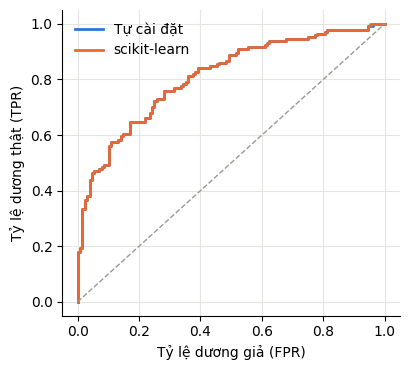

In [6]:
fig = viz.plot_roc(data.y_test, {"Tự cài đặt": p_sc, "scikit-learn": p_sk})
viz.save(fig, "5_roc.png")
plt.show()

## 5. Lưu mô hình

In [7]:
best = search.best_estimator_            # pipeline: chuẩn hóa + hồi quy logistic
joblib.dump(best, "saved_models/logistic_sklearn_pipeline.joblib")
print("Đã lưu pipeline vào saved_models/")

Đã lưu pipeline vào saved_models/
